# Matriz de provisión: enfoque simplificado separado
## Resumen
Este experimento estima tasas de pérdida lifetime por antigüedad con cohortes completas y las aplica a cuentas por cobrar actuales. Es una alternativa metodológica al motor por componentes para poblaciones elegibles; aquí no se determina elegibilidad contable.

## Contexto y métodos
Para bucket $b$, $LR_b=\sum_i shortfall_i^{PV}/\sum_i exposure_i$. La ponderación se hace por exposición, no promediando porcentajes por factura. ECL prospectiva = $\sum_s w_s\sum_b E_b\,clip(LR_b\,a_s,0,1)$.

### Supuestos
Cohortes cerradas sintéticas, shortfalls ya descontados, buckets mutuamente excluyentes y sin doble conteo de facturas entre cohortes. Multiplicadores de escenario suministrados, no estimados. La matriz es un ejemplo de implementación; validar requisitos de IFRS 9 para cuentas por cobrar, activos del contrato y arrendamientos antes de decidir su uso.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from src.multimodel import ProvisionMatrix
rng=np.random.default_rng(20261018)
buckets=["Corriente","1–30 días","31–60 días","61–90 días",">90 días"]
rows=[]
for b,rate in zip(buckets,[.01,.04,.12,.30,.65]):
    for cohort in range(20):
        exposure=float(rng.uniform(1000,10000))
        realized=float(rng.beta(rate*50,(1-rate)*50))
        rows.append({"bucket":b,"cohort":cohort,"exposure":exposure,"discounted_shortfall":exposure*realized})
history=pd.DataFrame(rows)
train=history.query("cohort < 14");test=history.query("cohort >= 14")
model=ProvisionMatrix().fit(train)
current=pd.DataFrame({"bucket":buckets,"exposure":[200000,80000,40000,20000,10000]})
scenarios={"base":(.6,1.),"adverse":(.3,1.35),"upside":(.1,.8)}

## Datos y resultados: tasas lifetime por bucket

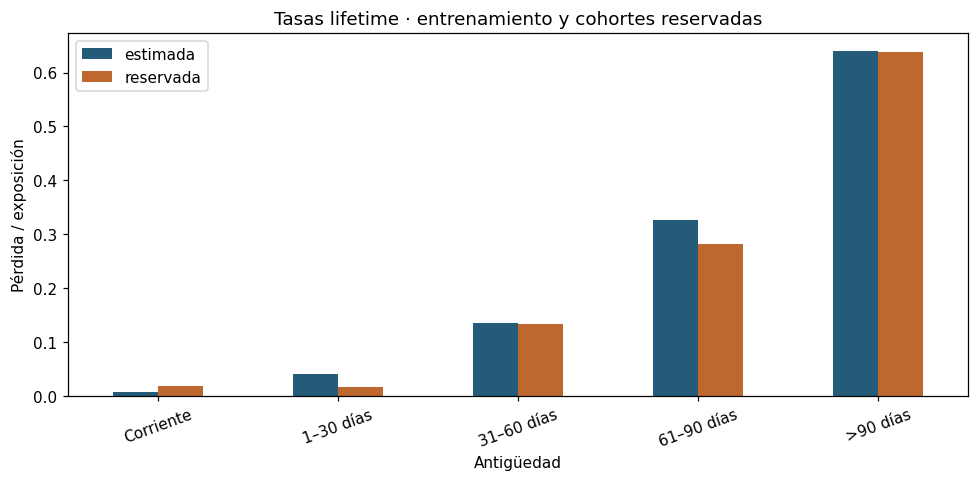

,estimada,reservada
bucket,,
Corriente,0.0071,0.0188
1–30 días,0.0403,0.0166
31–60 días,0.1359,0.1339
61–90 días,0.3269,0.2817
>90 días,0.6408,0.6387


In [2]:
observed=test.groupby("bucket")[["exposure","discounted_shortfall"]].sum()
comparison=pd.DataFrame({"estimada":model.rates,"reservada":observed.discounted_shortfall/observed.exposure}).reindex(buckets)
display(comparison.round(4))
fig,ax=plt.subplots(figsize=(9,4.5));comparison.plot.bar(ax=ax,color=["#245B78","#BE672F"],rot=20)
ax.set(title="Tasas lifetime · entrenamiento y cohortes reservadas",ylabel="Pérdida / exposición",xlabel="Antigüedad")
fig.tight_layout();plt.show()

### Aplicación prospectiva y reconciliación

In [3]:
current["tasa_historica"]=current.bucket.map(model.rates)
current["ecl_ponderada"]=model.predict(current,scenarios)
current["cobertura"]=current.ecl_ponderada/current.exposure
display(current.round(3))
base=model.predict(current,{"base":(1.,1.)}).sum()
weighted=current.ecl_ponderada.sum()
print(f"ECL histórica: {base:,.2f}; prospectiva: {weighted:,.2f}")
assert (current.ecl_ponderada>=0).all() and (current.ecl_ponderada<=current.exposure).all()
expected=sum(w*np.minimum(current.tasa_historica.to_numpy()*mult,1)*current.exposure.to_numpy() for w,mult in scenarios.values())
np.testing.assert_allclose(expected,current.ecl_ponderada)

ECL histórica: 23,033.22; prospectiva: 24,991.05


,bucket,exposure,tasa_historica,ecl_ponderada,cobertura
0,Corriente,200000,0.007,1550.234,0.008
1,1–30 días,80000,0.040,3498.638,0.044
2,31–60 días,40000,0.136,5896.505,0.147
3,61–90 días,20000,0.327,7093.196,0.355
4,>90 días,10000,0.641,6952.475,0.695


### Concentración del saldo y de la pérdida

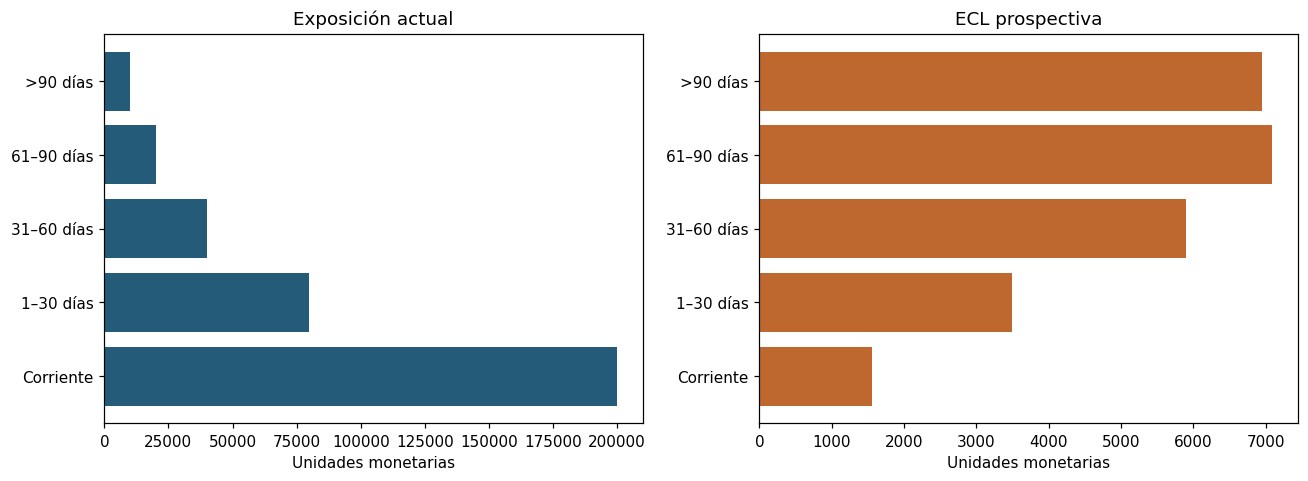

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(current.bucket,current.exposure,color="#245B78");axes[0].set(title="Exposición actual",xlabel="Unidades monetarias")
axes[1].barh(current.bucket,current.ecl_ponderada,color="#BE672F");axes[1].set(title="ECL prospectiva",xlabel="Unidades monetarias")
fig.tight_layout();plt.show()

### Un bucket desconocido exige una decisión explícita

In [5]:
try:
    model.predict(pd.DataFrame({"bucket":["sin_historia"],"exposure":[100.]}),scenarios)
except ValueError as error:
    print("Rechazo esperado:",error)
else:
    raise AssertionError("No se permite imputar silenciosamente una tasa cero")

Rechazo esperado: Known buckets and nonnegative exposure required


## Conclusiones y límites
No sumar las ECL de esta matriz a las del motor por componentes sobre las mismas cuentas. Las cohortes cerradas no resuelven censura ni cambios de mezcla. Los multiplicadores prospectivos requieren sustento económico y validación. Los buckets aquí no imponen una relación monotónica: la tasa se estima y se revisa, no se fuerza por apariencia.